# Разведочный анализ качества атмосферного воздуха в Германии

## 1. Введение

Цель данной работы — провести разведочный анализ данных (Exploratory Data Analysis, EDA) о качестве атмосферного воздуха на пяти выбранных городских транспортных станциях Германии.

Исследование охватывает период с 2015 по 2024 год включительно. В анализ включены шесть загрязнителей атмосферного воздуха:

- Угарный газ (CO);
- Диоксид азота (NO2);
- Озон (O3);
- Взвешенные частицы диаметром до 10 мкм (PM10);
- Мелкодисперсные частицы диаметром до 2.5 мкм (PM2.5);
- Диоксид серы (SO2).

В рамках исследования планируется изучить структуру и качество данных, оценить наличие и характер пропущенных значений, выявить потенциально ошибочные наблюдения и выбросы, исследовать распределения концентраций загрязнителей и определить взаимосвязи между ними.

Анализ проводится по пяти выбранным станциям. Это позволит не только изучить характеристики отдельных загрязнителей, но и сравнить полученные закономерности между станциями.

Полученные результаты позволят определить особенности и ограничения имеющихся данных, а также сформировать основу для последующих этапов университетского проекта.

## 2. Библиотеки и настройки проекта

В этом разделе подключаются библиотеки Python, определяются основные параметры исследования: период наблюдений, список выбранных станций, анализируемые загрязнители и пути к подготовленным наборам данных.

In [7]:
# Библиотеки для работы с данными
import pandas as pd
import numpy as np

# Библиотеки для визуализации
import matplotlib.pyplot as plt
import seaborn as sns

# Работа с путями и файловой системой
from pathlib import Path

# Настройки отображения таблиц
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Настройки графиков
sns.set_theme(style="whitegrid")

In [ ]:
STATIONS = {
    "DEMV022": "Rostock-Holbeinplatz",
    "DERP023": "Worms-Hagenstraße",
    "DEBY037": "München/Stachus",
    "DEST133": "Halle/Riebeckplatz",
    "DEBE065": "Berlin Frankfurter Allee"
}

POLLUTANTS = [
    "CO",
    "NO2",
    "O3",
    "PM10",
    "PM2.5",
    "SO2"
]

START_DATE = "2015-01-01"
END_DATE = "2024-12-31"

EXPECTED_HOURS = 87672

print("Количество станций:", len(STATIONS))
print("Количество загрязнителей:", len(POLLUTANTS))
print("Период исследования:", START_DATE, "-", END_DATE)
print("Ожидаемое количество часовых наблюдений:", EXPECTED_HOURS)

Количество станций: 5
Количество загрязнителей: 6
Период исследования: 2015-01-01 - 2024-12-31
Ожидаемое количество часовых наблюдений: 87672


In [ ]:
# Определение корневой папки проекта

PROJECT_DIR = Path.cwd()

# Поиск корневой папки проекта
while PROJECT_DIR != PROJECT_DIR.parent:
    if (PROJECT_DIR / "scripts").exists():
        break

    PROJECT_DIR = PROJECT_DIR.parent

# Путь к папке с подготовленными данными
DATA_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "comparative_stations"
)

# Пути к пяти CSV-файлам
STATION_FILES = {
    station_code: (
        DATA_DIR
        / station_code
        / f"{station_code}_hourly_2015_2024.csv"
    )
    for station_code in STATIONS
}

print("Корневая папка проекта:", PROJECT_DIR)
print("\nПапка с данными:", DATA_DIR)

print("\nПодготовленные файлы:")

for station_code, file_path in STATION_FILES.items():
    if file_path.exists():
        file_size = file_path.stat().st_size / (1024 ** 2)

        print(
            f"{station_code}: файл найден, "
            f"размер {file_size:.2f} MB"
        )
    else:
        print(f"{station_code}: файл не найден")

Корневая папка проекта: c:\Users\user\Desktop\Year_Project_Clean

Папка с данными: c:\Users\user\Desktop\Year_Project_Clean\data\processed\comparative_stations

Подготовленные файлы:
DEMV022: файл найден, размер 9.21 MB
DERP023: файл найден, размер 10.84 MB
DEBY037: файл найден, размер 9.97 MB
DEST133: файл найден, размер 9.24 MB
DEBE065: файл найден, размер 9.52 MB


## 3. Загрузка и объединение данных

В данном разделе загружаются подготовленные наборы данных пяти выбранных станций.

Для удобства распространения проекта подготовленные CSV-файлы размещаются в GitHub-репозитории. При запуске Notebook проверяется наличие файлов на локальном компьютере. Отсутствующие файлы автоматически скачиваются из репозитория и сохраняются в соответствующие папки проекта.

После загрузки данные объединяются в одну таблицу. При этом для каждого наблюдения сохраняется информация о станции, на которой оно было получено.


In [13]:
# Данные GitHub-репозитория

GITHUB_OWNER = "TomMul1er"
GITHUB_REPOSITORY = "AI-Project №1 Izvekov-Bobylev (IB)"
GITHUB_BRANCH = "main"

GITHUB_RAW_URL = (
    f"https://raw.githubusercontent.com/"
    f"{GITHUB_OWNER}/{GITHUB_REPOSITORY}/{GITHUB_BRANCH}"
)

print("GitHub repository:", GITHUB_OWNER + "/" + GITHUB_REPOSITORY)
print("Branch:", GITHUB_BRANCH)


GitHub repository: TomMul1er/AI-Project №1 Izvekov-Bobylev (IB)
Branch: main


In [ ]:
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from shutil import copyfileobj

if (
    GITHUB_OWNER == "YOUR_GITHUB_USERNAME"
    or GITHUB_REPOSITORY == "YOUR_REPOSITORY_NAME"
):
    raise ValueError(
        "Сначала укажи имя пользователя и название GitHub-репозитория."
    )

for station_code, file_path in STATION_FILES.items():

    if file_path.exists() and file_path.stat().st_size > 0:
        print(f"{station_code}: файл уже существует.")
        continue

    file_path.parent.mkdir(parents=True, exist_ok=True)

    relative_path = file_path.relative_to(PROJECT_DIR).as_posix()

    file_url = f"{GITHUB_RAW_URL}/{relative_path}"

    print(f"{station_code}: скачивание файла...")

    request = Request(
        file_url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    try:
        with urlopen(request, timeout=120) as response:
            with open(file_path, "wb") as output_file:
                copyfileobj(response, output_file)

        if file_path.stat().st_size == 0:
            file_path.unlink()
            raise ValueError("Скачанный файл пустой.")

        print(f"{station_code}: загрузка завершена.")

    except (HTTPError, URLError, TimeoutError, OSError, ValueError) as error:

        if file_path.exists():
            file_path.unlink()

        raise RuntimeError(
            f"Не удалось скачать данные для {station_code}.\n"
            f"Проверь ссылку и наличие файла в GitHub.\n"
            f"Адрес: {file_url}\n"
            f"Ошибка: {error}"
        ) from error

DEMV022: файл уже существует.
DERP023: файл уже существует.
DEBY037: файл уже существует.
DEST133: файл уже существует.
DEBE065: файл уже существует.


In [16]:
station_data = {}

for station_code, file_path in STATION_FILES.items():

    station = pd.read_csv(
        file_path,
        parse_dates=["Timestamp"],
        low_memory=False
    )

    station["station_code"] = station_code
    station["station_name"] = STATIONS[station_code]

    station_data[station_code] = station

    print(
        f"{station_code}: "
        f"{len(station):,} строк, "
        f"{len(station.columns)} столбцов"
    )

data = pd.concat(
    station_data.values(),
    ignore_index=True
)

print("\nОбщий размер объединённого набора данных:")
print(data.shape)

print("\nПервые пять строк:")
display(data.head())


DEMV022: 87,672 строк, 23 столбцов
DERP023: 87,672 строк, 23 столбцов
DEBY037: 87,672 строк, 23 столбцов
DEST133: 87,672 строк, 23 столбцов
DEBE065: 87,672 строк, 23 столбцов

Общий размер объединённого набора данных:
(438360, 23)

Первые пять строк:


,station_code,station_name,Timestamp,CO,CO_validity,CO_verification,NO2,NO2_validity,NO2_verification,O3,O3_validity,O3_verification,PM10,PM10_validity,PM10_verification,PM2.5,PM2.5_validity,PM2.5_verification,SO2,SO2_validity,SO2_verification,missing_pollutants_count,below_detection_limit_count
0,DEMV022,Rostock-Holbeinplatz,2015-01-01 00:00:00,0.310,1.000,1.000,26.500,1.000,1.000,23.700,1.000,1.000,92.840,1.000,1.000,86.240,1.000,1.000,3.100,1.000,1.000,0,0
1,DEMV022,Rostock-Holbeinplatz,2015-01-01 01:00:00,0.290,1.000,1.000,19.100,1.000,1.000,33.750,1.000,1.000,33.270,1.000,1.000,27.330,1.000,1.000,1.200,1.000,1.000,0,0
2,DEMV022,Rostock-Holbeinplatz,2015-01-01 02:00:00,0.280,1.000,1.000,18.400,1.000,1.000,NaN,-1.000,1.000,31.380,1.000,1.000,25.330,1.000,1.000,NaN,-1.000,1.000,2,0
3,DEMV022,Rostock-Holbeinplatz,2015-01-01 03:00:00,0.260,1.000,1.000,18.300,1.000,1.000,36.390,1.000,1.000,30.130,1.000,1.000,24.170,1.000,1.000,0.800,1.000,1.000,0,0
4,DEMV022,Rostock-Holbeinplatz,2015-01-01 04:00:00,0.280,1.000,1.000,21.800,1.000,1.000,35.370,1.000,1.000,30.800,1.000,1.000,24.620,1.000,1.000,1.000,1.000,1.000,0,0



## 4. Общий обзор данных

В этом разделе проводится первоначальное исследование объединённого набора данных пяти мониторинговых станций.

Сначала рассматриваются размер и структура таблицы, затем анализируются типы признаков и рассчитываются основные описательные статистики.

Особое внимание уделяется концентрациям шести загрязнителей, временным характеристикам наблюдений, идентификаторам станций и показателям качества измерений.

Полученные результаты позволят понять, какие данные доступны для дальнейшего анализа и какие особенности необходимо учитывать при их исследовании.

### 4.1. Размер и структура набора данных

In [17]:
print("Размер набора данных:")
print(f"Количество строк: {data.shape[0]:,}")
print(f"Количество столбцов: {data.shape[1]}")

print("\nКоличество наблюдений по станциям:")

station_counts = (
    data["station_code"]
    .value_counts()
    .reindex(STATIONS.keys())
)

display(station_counts.to_frame("Количество наблюдений"))

expected_total = len(STATIONS) * EXPECTED_HOURS

print(f"\nОжидаемое количество строк: {expected_total:,}")
print(f"Фактическое количество строк: {len(data):,}")

if len(data) == expected_total:
    print("Количество строк соответствует ожиданиям.")
else:
    print("Внимание: количество строк отличается от ожидаемого.")

Размер набора данных:
Количество строк: 438,360
Количество столбцов: 23

Количество наблюдений по станциям:


,Количество наблюдений
station_code,
DEMV022,87672
DERP023,87672
DEBY037,87672
DEST133,87672
DEBE065,87672



Ожидаемое количество строк: 438,360
Фактическое количество строк: 438,360
Количество строк соответствует ожиданиям.



### 4.2. Типы данных и структура признаков


In [18]:
data.info()

data_types = pd.DataFrame({
    "Тип данных": data.dtypes,
    "Количество непустых значений": data.count(),
    "Количество уникальных значений": data.nunique()
})

display(data_types)

<class 'pandas.DataFrame'>
RangeIndex: 438360 entries, 0 to 438359
Data columns (total 23 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   station_code                 438360 non-null  str           
 1   station_name                 438360 non-null  str           
 2   Timestamp                    438360 non-null  datetime64[us]
 3   CO                           396327 non-null  float64       
 4   CO_validity                  403296 non-null  float64       
 5   CO_verification              403296 non-null  float64       
 6   NO2                          395265 non-null  float64       
 7   NO2_validity                 403296 non-null  float64       
 8   NO2_verification             403296 non-null  float64       
 9   O3                           353447 non-null  float64       
 10  O3_validity                  368232 non-null  float64       
 11  O3_verification              368232 n

,Тип данных,Количество непустых значений,Количество уникальных значений
station_code,str,438360,5
station_name,str,438360,5
Timestamp,datetime64[us],438360,87672
CO,float64,396327,130531
CO_validity,float64,403296,4
CO_verification,float64,403296,1
NO2,float64,395265,191054
NO2_validity,float64,403296,4
NO2_verification,float64,403296,1
O3,float64,353447,196362



### 4.3. Основные описательные статистики

Для получения первоначального представления о распределении значений рассчитываются описательные статистики всех признаков.

Используется метод `describe(include='all')`, позволяющий получить сводную статистику как для числовых, так и для категориальных признаков.

Для числовых признаков рассматриваются количество наблюдений, среднее значение, стандартное отклонение, минимальное и максимальное значения, а также квартили.

Для категориальных признаков рассматриваются количество уникальных значений, наиболее часто встречающееся значение и частота его появления.


In [19]:
descriptive_statistics = data.describe(include="all").T

display(descriptive_statistics)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
station_code,438360,5,DEMV022,87672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
station_name,438360,5,Rostock-Holbeinplatz,87672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Timestamp,438360,NaN,NaN,NaN,2020-01-01 11:30:00,2015-01-01 00:00:00,2017-07-02 05:45:00,2020-01-01 11:30:00,2022-07-02 17:15:00,2024-12-31 23:00:00,NaN
CO,"396,327.000",NaN,NaN,NaN,0.306,0.035,0.210,0.271,0.360,3.433,0.143
CO_validity,"403,296.000",NaN,NaN,NaN,0.886,-99.000,1.000,1.000,1.000,2.000,2.913
CO_verification,"403,296.000",NaN,NaN,NaN,1.000,1.000,1.000,1.000,1.000,1.000,0.000
NO2,"395,265.000",NaN,NaN,NaN,28.595,-0.489,14.135,24.290,38.470,191.970,19.092
NO2_validity,"403,296.000",NaN,NaN,NaN,0.676,-99.000,1.000,1.000,1.000,2.000,5.443
NO2_verification,"403,296.000",NaN,NaN,NaN,1.000,1.000,1.000,1.000,1.000,1.000,0.000
O3,"353,447.000",NaN,NaN,NaN,42.601,-0.600,21.589,41.379,60.014,282.480,26.878



### 4.4. Классификация признаков

Для дальнейшего анализа важно различать признаки не только по техническому типу данных, но и по их назначению.

В исследуемом наборе выделяются три основные группы:

1. Концентрации загрязнителей — числовые признаки, непосредственно характеризующие качество воздуха.
2. Информация о станции и времени — признаки, позволяющие определить место и период проведения измерения.
3. Показатели качества измерений — специальные коды, характеризующие достоверность и статус зарегистрированных наблюдений.


In [22]:
station_columns = [
    column for column in ["station_code", "station_name"]
    if column in data.columns
]

time_columns = [
    column for column in ["Timestamp"]
    if column in data.columns
]

quality_columns = [
    column for column in data.columns
    if column.endswith("_validity")
    or column.endswith("_verification")
]

derived_columns = [
    column for column in [
        "missing_pollutants_count",
        "below_detection_limit_count"
    ]
    if column in data.columns
]

print("1. Концентрации загрязнителей:")
print(POLLUTANTS)

print("\n2. Информация о станциях:")
print(station_columns)

print("\n3. Временные признаки:")
print(time_columns)

print("\n4. Показатели качества измерений:")
print(quality_columns)

print("\n5. Производные показатели качества данных:")
print(derived_columns)

classified_columns = (
    POLLUTANTS
    + station_columns
    + time_columns
    + quality_columns
    + derived_columns
)

other_columns = [
    column for column in data.columns
    if column not in classified_columns
]

1. Концентрации загрязнителей:
['CO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2']

2. Информация о станциях:
['station_code', 'station_name']

3. Временные признаки:
['Timestamp']

4. Показатели качества измерений:
['CO_validity', 'CO_verification', 'NO2_validity', 'NO2_verification', 'O3_validity', 'O3_verification', 'PM10_validity', 'PM10_verification', 'PM2.5_validity', 'PM2.5_verification', 'SO2_validity', 'SO2_verification']

5. Производные показатели качества данных:
['missing_pollutants_count', 'below_detection_limit_count']


## 5. Анализ пропущенных значений

Пропущенные измерения являются важной особенностью данных о качестве атмосферного воздуха. Они могут возникать из-за временного отключения оборудования, технического обслуживания станций, проблем передачи данных или особенностей обработки и проверки измерений.

В данном разделе оценивается количество и доля недоступных измерений для каждого загрязнителя и каждой станции. Также исследуются полнота одновременных измерений всех шести загрязнителей, изменение доступности данных во времени и наиболее распространённые комбинации пропусков.

При анализе качества данных необходимо различать два случая:
- Отсутствующее измерение — концентрация не была доступна для анализа.
- Измерение со статусом Validity = 2 — значение зарегистрировано, но находится ниже предела обнаружения.

Измерения со статусом Validity = 2 учитываются при оценке доступности наблюдений, однако не включаются в расчёт статистик концентраций. Для описательной статистики используются только измерения со статусом Validity = 1.

In [23]:
missingness_rows = []

for station_code, group in data.groupby("station_code"):

    for pollutant in POLLUTANTS:

        validity_column = f"{pollutant}_validity"

        validity = pd.to_numeric(
            group[validity_column],
            errors="coerce"
        )

        valid_1 = validity.eq(1).sum()

        valid_2 = validity.eq(2).sum()

        available = validity.isin([1, 2]).sum()

        unavailable = len(group) - available

        missingness_rows.append({
            "station_code": station_code,
            "pollutant": pollutant,
            "total_hours": len(group),
            "validity_1": valid_1,
            "validity_2": valid_2,
            "available_measurements": available,
            "unavailable_measurements": unavailable,
            "coverage_percent": available / len(group) * 100,
            "missing_percent": unavailable / len(group) * 100
        })

missingness_summary = pd.DataFrame(missingness_rows)

display(
    missingness_summary.round(2)
)

,station_code,pollutant,total_hours,validity_1,validity_2,available_measurements,unavailable_measurements,coverage_percent,missing_percent
0,DEBE065,CO,87672,85910,1350,87260,412,99.530,0.470
1,DEBE065,NO2,87672,86964,171,87135,537,99.390,0.610
2,DEBE065,O3,87672,54227,2829,57056,30616,65.080,34.920
3,DEBE065,PM10,87672,86877,3,86880,792,99.100,0.900
4,DEBE065,PM2.5,87672,43521,0,43521,44151,49.640,50.360
5,DEBE065,SO2,87672,20396,26685,47081,40591,53.700,46.300
6,DEBY037,CO,87672,87452,0,87452,220,99.750,0.250
7,DEBY037,NO2,87672,87096,0,87096,576,99.340,0.660
8,DEBY037,O3,87672,79698,4081,83779,3893,95.560,4.440
9,DEBY037,PM10,87672,86920,47,86967,705,99.200,0.800


In [ ]:
total_measurements = len(data) * len(POLLUTANTS)

available_measurements = (
    missingness_summary["available_measurements"].sum()
)

unavailable_measurements = (
    missingness_summary["unavailable_measurements"].sum()
)

overall_coverage = (
    available_measurements / total_measurements * 100
)

overall_missingness = (
    unavailable_measurements / total_measurements * 100
)

print("ОБЩАЯ ПОЛНОТА НАБОРА ДАННЫХ")
print(f"Всего возможных измерений: {total_measurements:,}")
print(f"Доступных измерений: {available_measurements:,}")
print(f"Недоступных измерений: {unavailable_measurements:,}")

print(f"\nДоля доступных измерений: {overall_coverage:.2f}%")
print(f"Доля недоступных измерений: {overall_missingness:.2f}%")

ОБЩАЯ ПОЛНОТА НАБОРА ДАННЫХ
Всего возможных измерений: 2,630,160
Доступных измерений: 2,145,253
Недоступных измерений: 484,907

Доля доступных измерений: 81.56%
Доля недоступных измерений: 18.44%


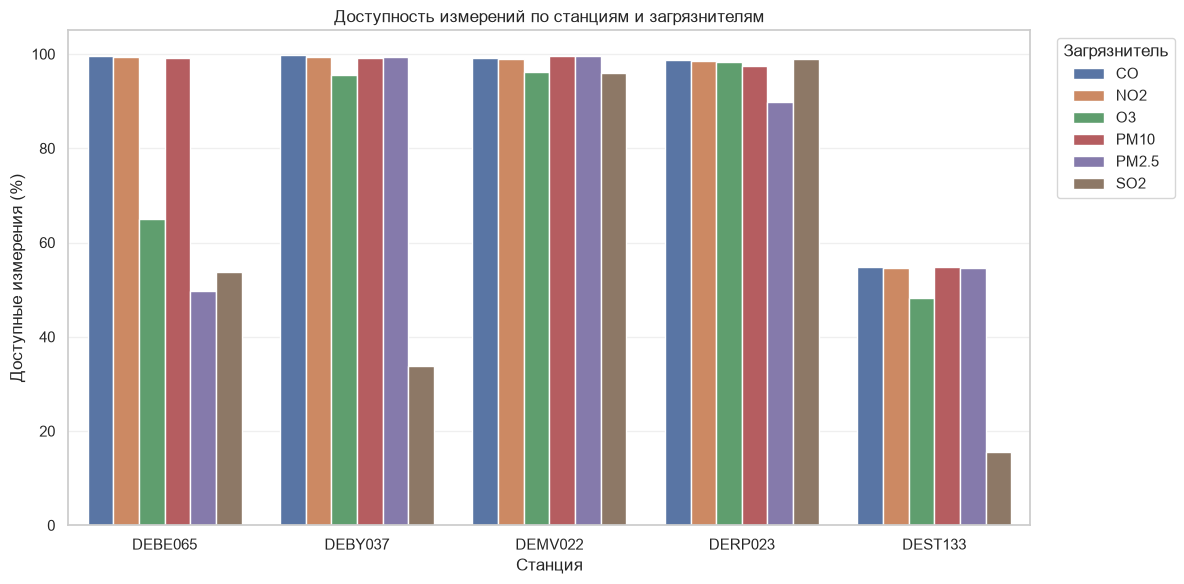

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missingness_summary,
    x="station_code",
    y="coverage_percent",
    hue="pollutant"
)

plt.title("Доступность измерений по станциям и загрязнителям")
plt.xlabel("Станция")
plt.ylabel("Доступные измерения (%)")
plt.ylim(0, 105)

plt.legend(
    title="Загрязнитель",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [26]:
availability = pd.DataFrame(index=data.index)

for pollutant in POLLUTANTS:

    validity_column = f"{pollutant}_validity"

    validity = pd.to_numeric(
        data[validity_column],
        errors="coerce"
    )

    availability[pollutant] = validity.isin([1, 2])

availability["station_code"] = data["station_code"]

availability["available_pollutants_count"] = (
    availability[POLLUTANTS].sum(axis=1)
)

availability["all_six_available"] = (
    availability["available_pollutants_count"] == len(POLLUTANTS)
)

complete_hours_summary = (
    availability.groupby("station_code")
    .agg(
        total_hours=("all_six_available", "size"),
        complete_hours=("all_six_available", "sum")
    )
)

complete_hours_summary["complete_percent"] = (
    complete_hours_summary["complete_hours"]
    / complete_hours_summary["total_hours"] * 100
)

display(complete_hours_summary.round(2))


,total_hours,complete_hours,complete_percent
station_code,,,
DEBE065,87672,3633,4.140
DEBY037,87672,25418,28.990
DEMV022,87672,82922,94.580
DERP023,87672,74273,84.720
DEST133,87672,7902,9.010


### 5.2. Полнота почасовых данных по всем шести загрязнителям

Для оценки общей полноты данных рассматривается количество часов, в течение которых на каждой станции доступны измерения всех шести загрязнителей.

Час считается полным, если каждый из шести загрязнителей имеет статус Validity = 1 или Validity = 2.

Результаты представлены в виде сравнительной диаграммы, позволяющей оценить различия в полноте данных между пятью станциями.

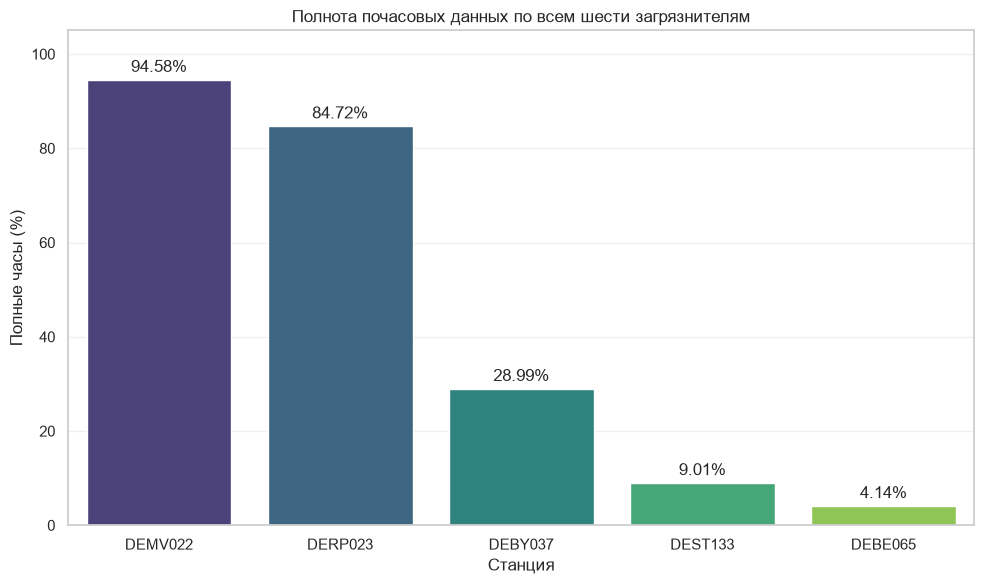

In [35]:
complete_hours = (
    complete_hours_summary
    .reindex(STATIONS.keys())
    .reset_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=complete_hours,
    x="station_code",
    y="complete_percent",
    hue="station_code",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Полнота почасовых данных по всем шести загрязнителям")
plt.xlabel("Станция")
plt.ylabel("Полные часы (%)")
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

### 5.3. Доступность проверенных измерений по станциям и загрязнителям

Для более детального сравнения исследуется доступность измерений каждого загрязнителя на каждой станции

Доступными считаются измерения со статусами Validity = 1 и Validity = 2

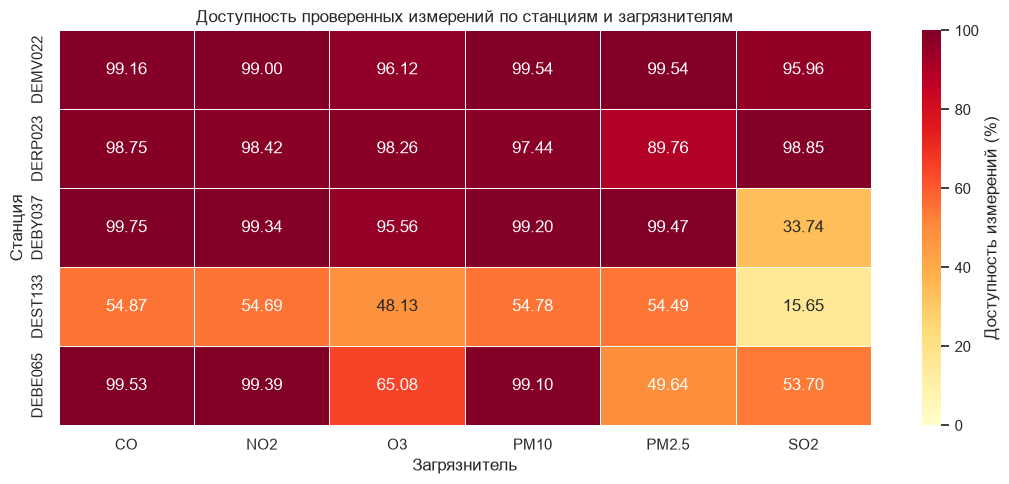

In [36]:
coverage_matrix = missingness_summary.pivot(
    index="station_code",
    columns="pollutant",
    values="coverage_percent"
).reindex(
    index=STATIONS.keys(),
    columns=POLLUTANTS
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    coverage_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Доступность измерений (%)"}
)

plt.title("Доступность проверенных измерений по станциям и загрязнителям")
plt.xlabel("Загрязнитель")
plt.ylabel("Станция")

plt.tight_layout()
plt.show()

### 6. Анализ распределений концентраций

В данном разделе исследуются распределения концентраций шести загрязнителей: CO, NO₂, O₃, PM10, PM2.5 и SO₂.

Для анализа используются только измерения со статусами Validity = 1 и Verification = 1. Измерения со статусом Validity = 2 не включаются, поскольку они соответствуют значениям ниже предела обнаружения и не должны рассматриваться как обычные числовые концентрации.

Некорректные и недоступные измерения заменяются на пропущенные значения. При этом исходный DataFrame `data` остаётся без изменений.

In [38]:
concentration_data = data.copy()

for pollutant in POLLUTANTS:
    valid_measurements = (
        (concentration_data[f"{pollutant}_validity"] == 1)
        & (concentration_data[f"{pollutant}_verification"] == 1)
    )

    concentration_data[pollutant] = concentration_data[pollutant].where(
        valid_measurements
    )

### 6.1 Описательная статистика

Для первоначального изучения распределений рассчитываются основные статистические характеристики каждого загрязнителя: количество доступных измерений, среднее значение, стандартное отклонение, минимум, медиана, квартили и максимум.

Эти показатели позволяют оценить типичные уровни концентраций, разброс значений и наличие потенциально экстремальных наблюдений.

In [39]:
concentration_summary = concentration_data[POLLUTANTS].describe().T

concentration_summary["valid_percent"] = (
    concentration_summary["count"] / len(concentration_data) * 100
)

concentration_summary = concentration_summary.rename(columns={
    "count": "Количество измерений",
    "valid_percent": "Валидные измерения (%)",
    "mean": "Среднее",
    "std": "Стандартное отклонение",
    "min": "Минимум",
    "25%": "25-й процентиль",
    "50%": "Медиана",
    "75%": "75-й процентиль",
    "max": "Максимум"
})

concentration_summary.index.name = "Загрязнитель"

display(concentration_summary.round(3))

,Количество измерений,Среднее,Стандартное отклонение,Минимум,25-й процентиль,Медиана,75-й процентиль,Максимум,Валидные измерения (%)
Загрязнитель,,,,,,,,,
CO,"394,966.000",0.306,0.143,0.070,0.211,0.272,0.360,3.433,90.101
NO2,"392,476.000",28.778,19.035,1.000,14.327,24.442,38.600,191.970,89.533
O3,"339,513.000",44.301,26.053,0.930,24.143,42.817,60.872,282.480,77.451
PM10,"392,171.000",19.967,17.527,0.510,10.909,16.647,25.040,"3,407.470",89.463
PM2.5,"332,194.000",12.085,11.305,0.503,5.938,9.455,15.300,"1,219.810",75.781
SO2,"120,747.000",2.324,4.065,0.300,0.700,1.500,2.934,699.410,27.545


Наибольшая доля валидных измерений наблюдается у CO (90,10%), NO2 (89,53%) и PM10 (89,46%). Для O3 и PM2.5 этот показатель составляет 77,45% и 75,78% соответственно. Наименьшая доля наблюдений приходится на SO2 — 27,55%.

Различия также заметны при сравнении средних значений и медиан. Для всех шести загрязнителей среднее значение превышает медиану. Это указывает на возможную правостороннюю асимметрию распределений, при которой относительно небольшое количество высоких концентраций увеличивает среднее значение.

Особенно заметна разница между 75-м процентилем и максимальным значением для PM10, PM2.5 и SO2. Например, максимальная концентрация PM10 составляет 3407,47 µg/m³, тогда как 75-й процентиль равен 25,04 µg/m³. Подобные различия указывают на наличие очень высоких наблюдений, которые требуют дополнительного изучения.

Таким образом, для более полного понимания распределений необходимо рассмотреть не только средние значения, но и форму распределений, разброс концентраций и отдельные экстремальные наблюдения.

### 6.3 Проверка экстремальных значений

Для дополнительного исследования распределений рассматриваются пять наибольших измерений каждого загрязнителя.

Для каждого наблюдения проверяются станция, дата и время измерения, а также статусы Validity и Verification. Это позволяет определить, на каких станциях и в какие моменты времени были зафиксированы наиболее высокие концентрации.

In [41]:
extreme_values = []

for pollutant in POLLUTANTS:
    columns = [
        "station_code",
        "station_name",
        "Timestamp",
        pollutant,
        f"{pollutant}_validity",
        f"{pollutant}_verification"
    ]

    pollutant_extremes = (
        concentration_data[columns]
        .dropna(subset=[pollutant])
        .nlargest(5, pollutant)
        .copy()
    )

    pollutant_extremes["pollutant"] = pollutant

    pollutant_extremes = pollutant_extremes.rename(columns={
        pollutant: "concentration",
        f"{pollutant}_validity": "validity",
        f"{pollutant}_verification": "verification"
    })

    extreme_values.append(pollutant_extremes)

extreme_values = pd.concat(extreme_values, ignore_index=True)

extreme_values = extreme_values[
    [
        "pollutant",
        "station_code",
        "station_name",
        "Timestamp",
        "concentration",
        "validity",
        "verification"
    ]
]

display(
    extreme_values.sort_values(
        ["pollutant", "concentration"],
        ascending=[True, False]
    ).round(3)
)

C:\Users\user\AppData\Local\Temp\ipykernel_15800\2598777127.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


,pollutant,station_code,station_name,Timestamp,concentration,validity,verification
0,CO,DERP023,Worms-Hagenstraße,2019-02-16 20:00:00,3.433,1.000,1.000
1,CO,DEBY037,München/Stachus,2020-11-06 15:00:00,3.355,1.000,1.000
2,CO,DERP023,Worms-Hagenstraße,2015-12-07 19:00:00,3.347,1.000,1.000
3,CO,DERP023,Worms-Hagenstraße,2015-12-07 18:00:00,3.252,1.000,1.000
4,CO,DERP023,Worms-Hagenstraße,2019-02-16 19:00:00,3.168,1.000,1.000
5,NO2,DEBY037,München/Stachus,2016-12-08 16:00:00,191.970,1.000,1.000
6,NO2,DEBY037,München/Stachus,2015-08-07 20:00:00,190.950,1.000,1.000
7,NO2,DEBY037,München/Stachus,2016-12-08 17:00:00,183.220,1.000,1.000
8,NO2,DEBE065,Berlin Frankfurter Allee,2016-09-13 15:00:00,183.150,1.000,1.000
9,NO2,DEBY037,München/Stachus,2015-08-28 20:00:00,180.910,1.000,1.000


Результаты проверки экстремальных значений показывают, что наиболее высокие концентрации PM10, PM2.5 и SO2 неоднократно наблюдались в период новогодних праздников. Например, максимальные значения PM10 и SO2 были зафиксированы на станции DEBE065, а максимальная концентрация PM2.5 — на станции DEBY037.

Такая временная близость экстремальных наблюдений заслуживает дополнительного внимания.

Все рассмотренные измерения имеют статусы Validity = 1 и Verification = 1. Поэтому на данном этапе они сохраняются в наборе данных и рассматриваются как потенциально экстремальные наблюдения, требующие дальнейшего изучения.

### 6.4 Выявление потенциально экстремальных значений

Для более систематического исследования распределений используется межквартильный размах (IQR).

Для каждого загрязнителя рассчитывается количество и доля таких наблюдений. Полученные значения используются для оценки выраженности экстремальных наблюдений в распределениях.

In [42]:
iqr_results = []

for pollutant in POLLUTANTS:
    values = concentration_data[pollutant].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    iqr_results.append({
        "pollutant": pollutant,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percent": len(outliers) / len(values) * 100
    })

iqr_summary = pd.DataFrame(iqr_results)

iqr_summary = iqr_summary.rename(columns={
    "pollutant": "Загрязнитель",
    "lower_bound": "Нижняя граница",
    "upper_bound": "Верхняя граница",
    "outlier_count": "Количество экстремальных значений",
    "outlier_percent": "Экстремальные значения (%)"
})

display(iqr_summary.round(3))

,Загрязнитель,Нижняя граница,Верхняя граница,Количество экстремальных значений,Экстремальные значения (%)
0,CO,-0.012,0.583,16511,4.180
1,NO2,-22.083,75.010,10897,2.776
2,O3,-30.951,115.967,3202,0.943
3,PM10,-10.287,46.236,17457,4.451
4,PM2.5,-8.105,29.343,16717,5.032
5,SO2,-2.651,6.285,6062,5.020


Результаты применения метода межквартильного размаха показывают, что доля потенциально экстремальных значений различается между загрязнителями.

Наибольшая доля таких наблюдений обнаружена для PM2.5 (5,03%) и SO2 (5,02%), тогда как для O3 она составляет менее 1%. Для CO и PM10 доля потенциально экстремальных значений также превышает 4%.

Все рассчитанные нижние границы оказались отрицательными, в то время как фактические минимальные концентрации положительны. Следовательно, выявленные методом IQR экстремальные наблюдения находятся выше верхних границ распределений.

При этом расчёты выполнялись по совокупности данных пяти станций. Поэтому обнаруженные значения рассматриваются как потенциально экстремальные, а не как ошибки измерений.

### 6.5 Визуализация распределений концентраций

Для изучения формы распределений строятся гистограммы концентраций всех шести загрязнителей.

Поскольку для некоторых загрязнителей наблюдается значительная разница между типичными и максимальными значениями, для горизонтальной оси используется логарифмическая шкала. Это позволяет нагляднее представить распределения с выраженным правым хвостом и не скрывать высокие концентрации.

Каждый загрязнитель отображается на отдельном графике. При этом используются только измерения со статусами Validity = 1 и Verification = 1. Исходные значения концентраций не преобразуются и не удаляются.

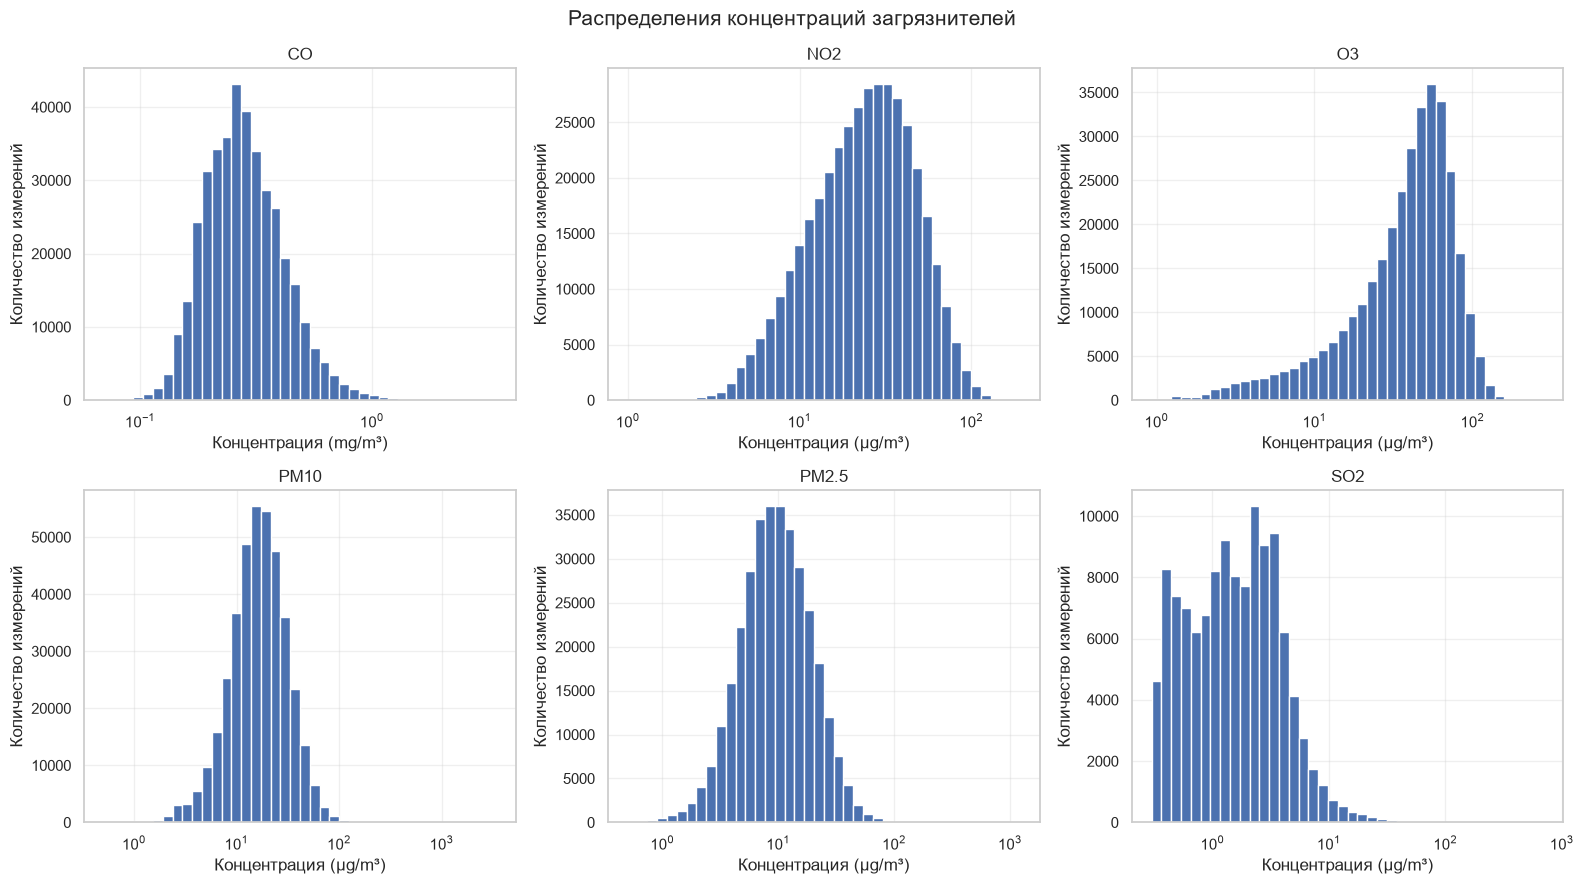

In [43]:
units = {
    "CO": "mg/m³",
    "NO2": "µg/m³",
    "O3": "µg/m³",
    "PM10": "µg/m³",
    "PM2.5": "µg/m³",
    "SO2": "µg/m³"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, pollutant in zip(axes, POLLUTANTS):
    values = concentration_data[pollutant].dropna()

    bins = np.logspace(
        np.log10(values.min()),
        np.log10(values.max()),
        41
    )

    ax.hist(values, bins=bins, edgecolor="white")
    ax.set_xscale("log")

    ax.set_title(pollutant)
    ax.set_xlabel(f"Концентрация ({units[pollutant]})")
    ax.set_ylabel("Количество измерений")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Распределения концентраций загрязнителей",
    fontsize=15
)

plt.tight_layout()
plt.show()

### 6.6 Сравнение распределений концентраций между станциями

Для исследования пространственных различий сравниваются распределения концентраций загрязнителей на пяти выбранных станциях.

Для каждого загрязнителя строится отдельная диаграмма размаха.

Поскольку ранее были обнаружены значительные различия между типичными и экстремальными концентрациями, для вертикальной оси используется логарифмическая шкала.

Для повышения наглядности потенциально экстремальные точки не отображаются на диаграммах. При этом сами измерения сохраняются в исходном наборе данных и продолжают учитываться в расчётах.

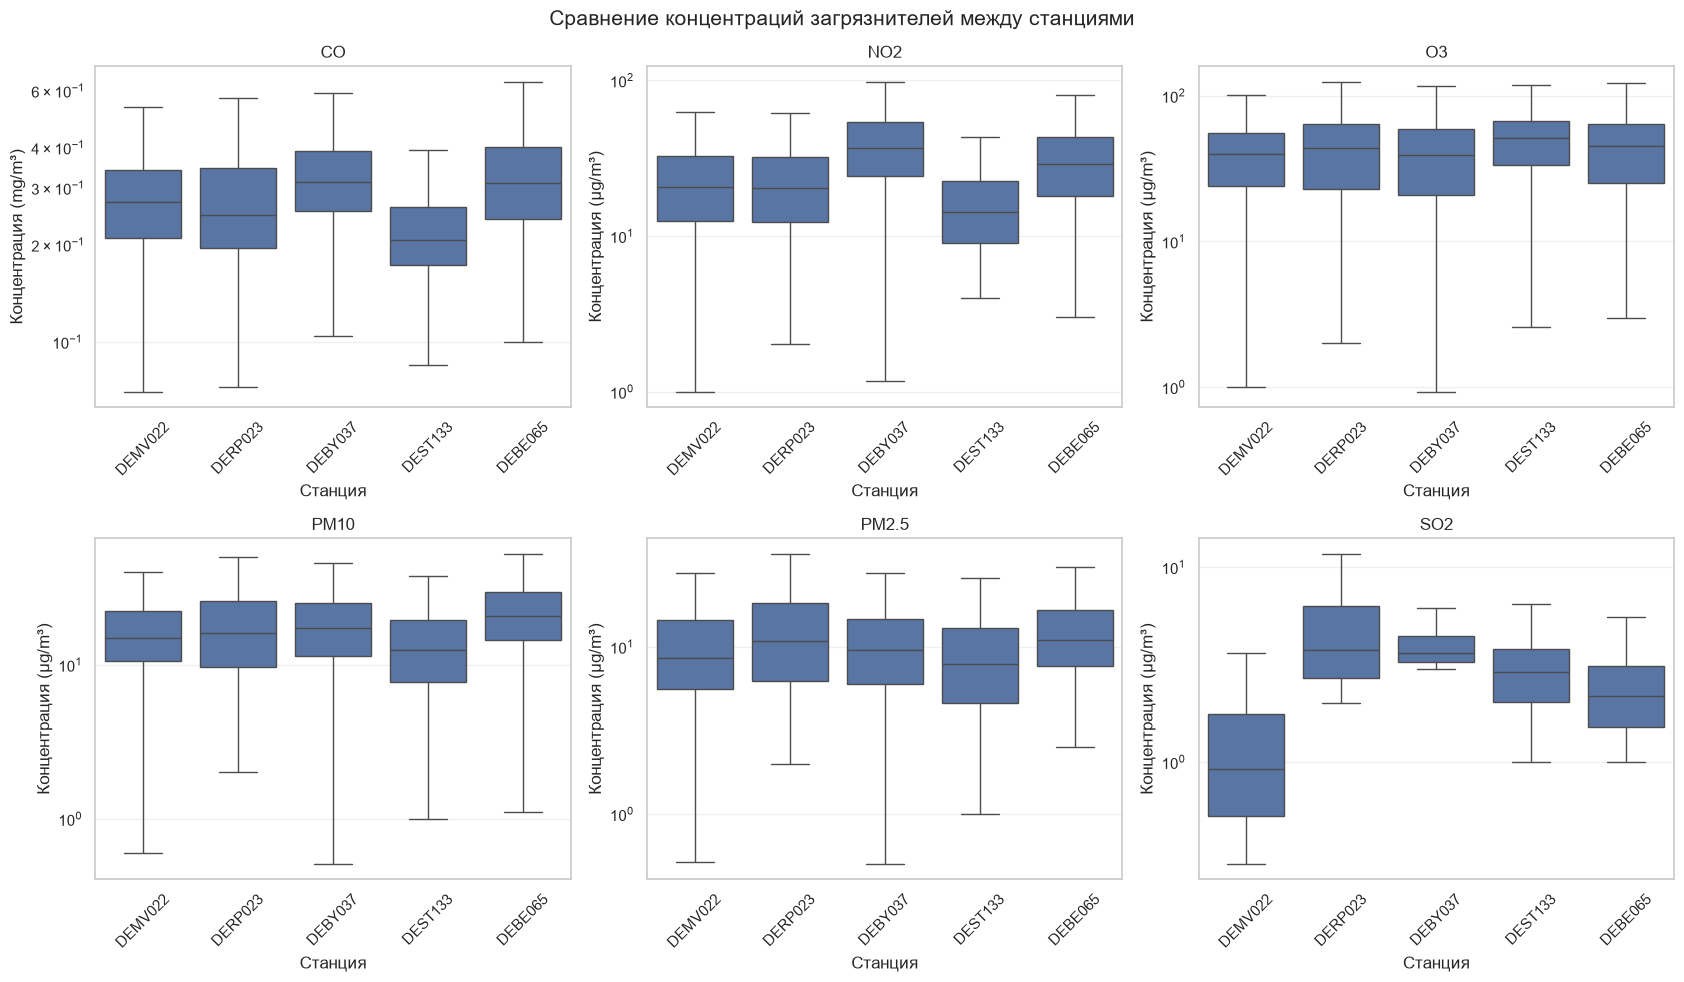

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

station_order = list(STATIONS.keys())

for ax, pollutant in zip(axes, POLLUTANTS):
    sns.boxplot(
        data=concentration_data,
        x="station_code",
        y=pollutant,
        order=station_order,
        showfliers=False,
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_title(pollutant)
    ax.set_xlabel("Станция")
    ax.set_ylabel(f"Концентрация ({units[pollutant]})")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Сравнение концентраций загрязнителей между станциями",
    fontsize=15
)

plt.tight_layout()
plt.show()

# 7. Анализ временной динамики концентраций

Рассматриваются долгосрочные изменения концентраций, различия между отдельными часами суток и днями недели.

Для анализа используются измерения со статусами Validity = 1 и Verification = 1.

## 7.1 Подготовка временных признаков

Для исследования временных закономерностей из временной метки измерений выделяются год, месяц, час суток и день недели.

Полученные признаки будут использоваться для группировки наблюдений и последующего сравнения концентраций в различные временные периоды.

In [49]:
temporal_data = concentration_data.copy()

temporal_data["Timestamp"] = pd.to_datetime(
    temporal_data["Timestamp"]
)

temporal_data["year"] = temporal_data["Timestamp"].dt.year
temporal_data["month"] = temporal_data["Timestamp"].dt.month
temporal_data["hour"] = temporal_data["Timestamp"].dt.hour
temporal_data["day_of_week"] = temporal_data["Timestamp"].dt.dayofweek

temporal_data["day_type"] = np.where(
    temporal_data["day_of_week"] >= 5,
    "Выходной",
    "Рабочий день"
)

display(temporal_data.head())

,station_code,station_name,Timestamp,CO,CO_validity,CO_verification,NO2,NO2_validity,NO2_verification,O3,O3_validity,O3_verification,PM10,PM10_validity,PM10_verification,PM2.5,PM2.5_validity,PM2.5_verification,SO2,SO2_validity,SO2_verification,missing_pollutants_count,below_detection_limit_count,year,month,hour,day_of_week,day_type
0,DEMV022,Rostock-Holbeinplatz,2015-01-01 00:00:00,0.310,1.000,1.000,26.500,1.000,1.000,23.700,1.000,1.000,92.840,1.000,1.000,86.240,1.000,1.000,3.100,1.000,1.000,0,0,2015,1,0,3,Рабочий день
1,DEMV022,Rostock-Holbeinplatz,2015-01-01 01:00:00,0.290,1.000,1.000,19.100,1.000,1.000,33.750,1.000,1.000,33.270,1.000,1.000,27.330,1.000,1.000,1.200,1.000,1.000,0,0,2015,1,1,3,Рабочий день
2,DEMV022,Rostock-Holbeinplatz,2015-01-01 02:00:00,0.280,1.000,1.000,18.400,1.000,1.000,NaN,-1.000,1.000,31.380,1.000,1.000,25.330,1.000,1.000,NaN,-1.000,1.000,2,0,2015,1,2,3,Рабочий день
3,DEMV022,Rostock-Holbeinplatz,2015-01-01 03:00:00,0.260,1.000,1.000,18.300,1.000,1.000,36.390,1.000,1.000,30.130,1.000,1.000,24.170,1.000,1.000,0.800,1.000,1.000,0,0,2015,1,3,3,Рабочий день
4,DEMV022,Rostock-Holbeinplatz,2015-01-01 04:00:00,0.280,1.000,1.000,21.800,1.000,1.000,35.370,1.000,1.000,30.800,1.000,1.000,24.620,1.000,1.000,1.000,1.000,1.000,0,0,2015,1,4,3,Рабочий день


## 7.2 Годовая динамика концентраций

Для исследования долгосрочных изменений концентраций рассчитываются годовые медианные значения каждого загрязнителя отдельно для каждой станции за период 2015–2024 годов.

Медиана используется в качестве основной характеристики годового уровня концентрации, поскольку она менее чувствительна к экстремальным наблюдениям по сравнению со средним арифметическим.

In [51]:
annual_medians = (
    temporal_data
    .groupby(["station_code", "year"])[POLLUTANTS]
    .median()
    .reset_index()
)

annual_counts = (
    temporal_data
    .groupby(["station_code", "year"])[POLLUTANTS]
    .count()
    .reset_index()
)
yearly_expected_hours = pd.DataFrame({
    "year": range(2015, 2025)
})

yearly_expected_hours["expected_hours"] = yearly_expected_hours["year"].apply(
    lambda year: 8784 if pd.Timestamp(year=year, month=1, day=1).is_leap_year else 8760
)

annual_coverage = annual_counts.merge(
    yearly_expected_hours,
    on="year"
)

for pollutant in POLLUTANTS:
    annual_coverage[pollutant] = (
        annual_coverage[pollutant]
        / annual_coverage["expected_hours"]
        * 100
    )

display(
    annual_coverage[
        ["station_code", "year"] + POLLUTANTS
    ].round(2)
)

,station_code,year,CO,NO2,O3,PM10,PM2.5,SO2
0,DEBE065,2015,92.160,98.900,0.000,98.470,0.000,80.170
1,DEBE065,2016,91.440,99.430,0.000,99.600,0.000,83.800
2,DEBE065,2017,99.450,99.270,0.000,99.250,0.000,25.260
3,DEBE065,2018,98.150,97.800,47.560,97.650,0.000,18.580
4,DEBE065,2019,99.540,99.550,93.180,99.690,0.000,17.760
5,DEBE065,2020,99.780,99.090,94.750,98.710,98.710,7.000
6,DEBE065,2021,99.750,99.260,94.630,99.730,99.730,0.000
7,DEBE065,2022,99.920,99.750,94.420,99.930,99.930,0.000
8,DEBE065,2023,99.780,99.600,96.920,98.030,98.030,0.000
9,DEBE065,2024,99.930,99.270,97.040,99.870,99.870,0.000


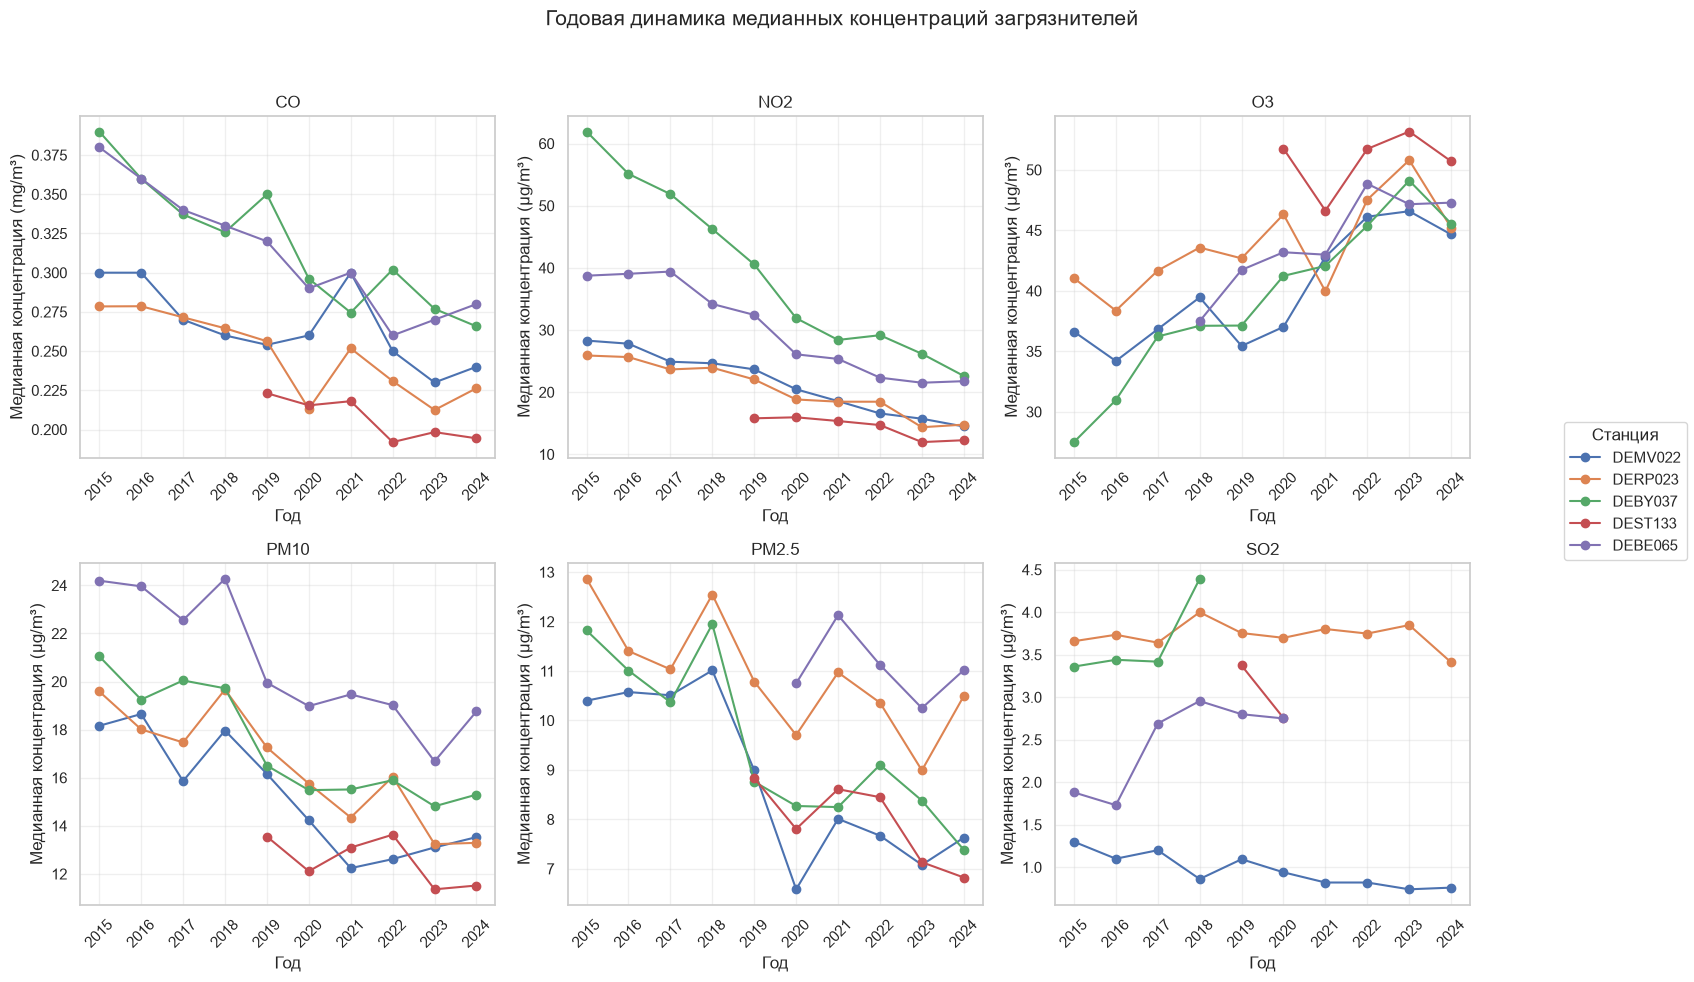

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

station_order = list(STATIONS.keys())

for i, (ax, pollutant) in enumerate(zip(axes, POLLUTANTS)):
    for station in station_order:
        station_values = annual_medians[
            annual_medians["station_code"] == station
        ].sort_values("year")

        ax.plot(
            station_values["year"],
            station_values[pollutant],
            marker="o",
            label=station
        )

    ax.set_title(pollutant)
    ax.set_xlabel("Год")
    ax.set_ylabel(f"Медианная концентрация ({units[pollutant]})")
    ax.set_xticks(range(2015, 2025))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

    if i == 0:
        handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Станция",
    loc="center right"
)

fig.suptitle(
    "Годовая динамика медианных концентраций загрязнителей",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 0.88, 0.95])
plt.show()

Годовая динамика медианных концентраций показывает различия в изменении уровней загрязнителей на выбранных станциях за период исследования.

Для CO и NO2 на всех пяти станциях наблюдается снижение годовых медианных концентраций. Аналогичная тенденция прослеживается для PM10. Для PM2.5 снижение заметно на большинстве станций, хотя характер изменений различается.

Для O3 на большинстве станций наблюдается увеличение медианных концентраций. При этом динамика не является полностью одинаковой: на отдельных станциях значения колеблются между годами.

Для SO2 общую временную тенденцию определить сложнее из-за низкой и неравномерной полноты данных на большинстве станций. Наиболее продолжительный ряд наблюдений имеется на DEMV022, тогда как на других станциях измерения доступны лишь для части исследуемого периода или имеют низкую полноту.

Следует учитывать, что временные ряды отдельных загрязнителей начинаются и заканчиваются в разные годы. Например, на DEST133 валидные измерения отсутствуют в 2015–2018 годах, а для PM2.5 на DEBE065 они отсутствуют до 2020 года.

## 7.4 Суточная динамика концентраций

Для исследования суточных закономерностей рассчитываются медианные концентрации каждого загрязнителя отдельно для каждой станции и каждого часа суток.

Это позволяет определить, в какие часы обычно наблюдаются более высокие и более низкие концентрации загрязнителей.

In [60]:
hourly_medians = (
    temporal_data
    .groupby(["station_code", "hour"])[POLLUTANTS]
    .median()
    .reset_index()
)

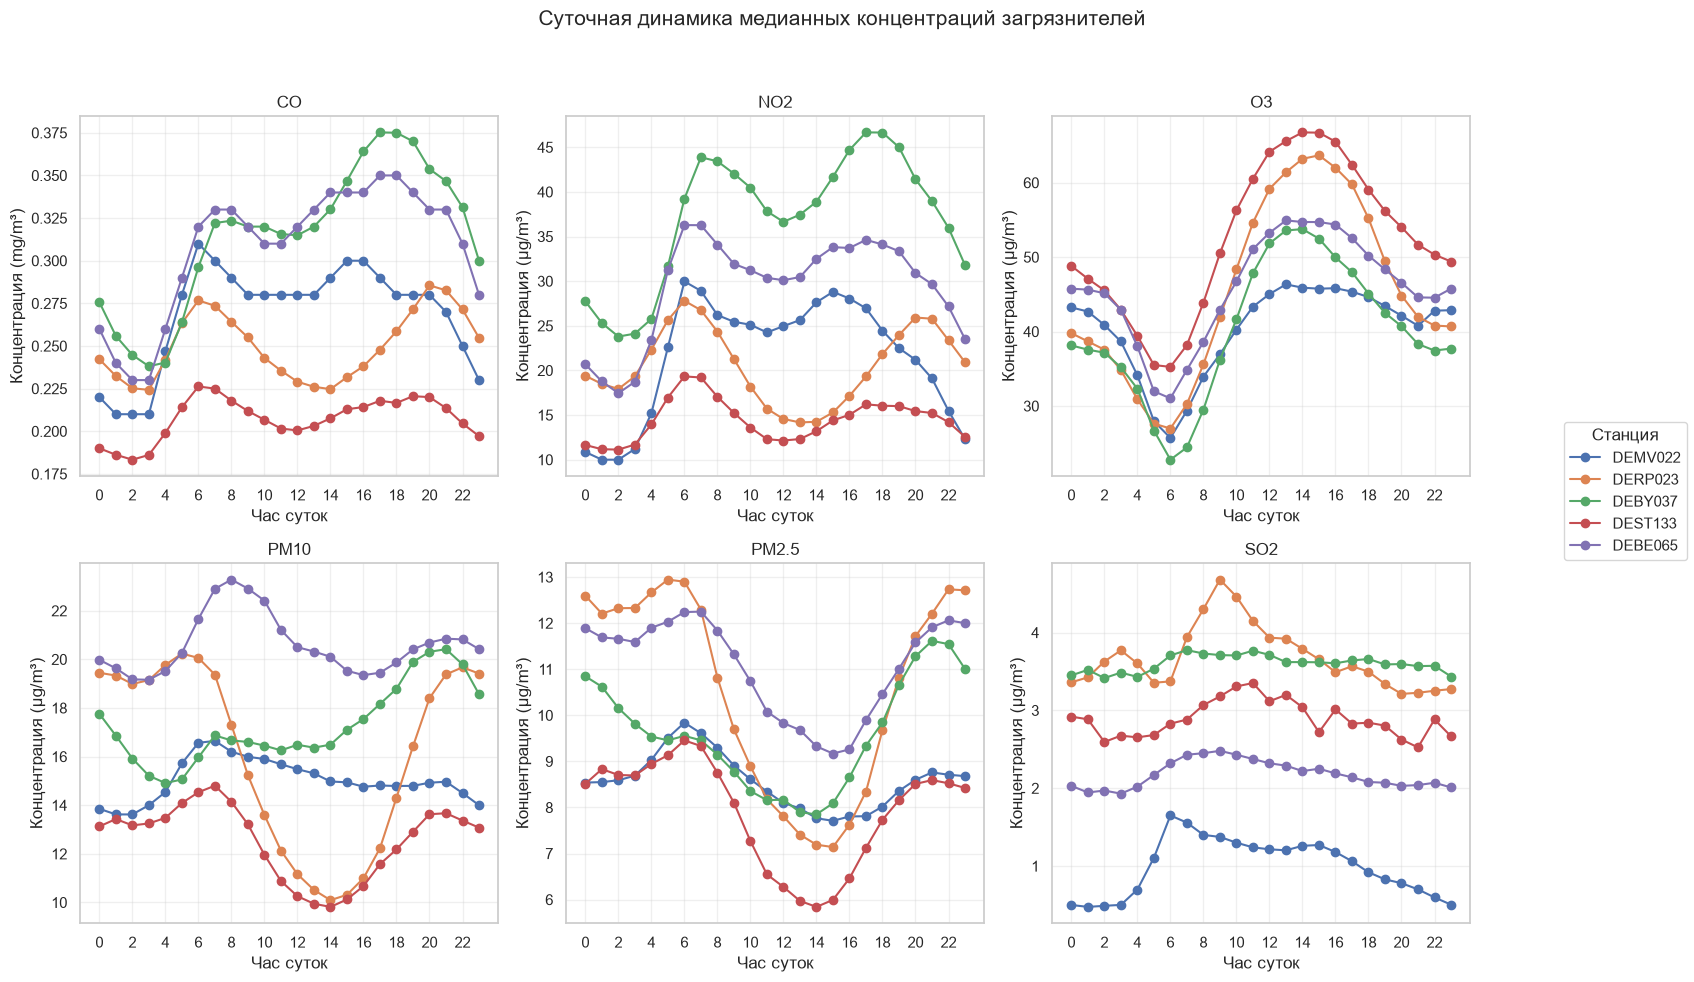

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

station_order = list(STATIONS.keys())

for i, (ax, pollutant) in enumerate(zip(axes, POLLUTANTS)):
    for station in station_order:
        station_values = hourly_medians[
            hourly_medians["station_code"] == station
        ].sort_values("hour")

        ax.plot(
            station_values["hour"],
            station_values[pollutant],
            marker="o",
            label=station
        )

    ax.set_title(pollutant)
    ax.set_xlabel("Час суток")
    ax.set_ylabel(f"Концентрация ({units[pollutant]})")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

    if i == 0:
        handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Станция",
    loc="center right"
)

fig.suptitle(
    "Суточная динамика медианных концентраций загрязнителей",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 0.88, 0.95])
plt.show()

Результаты суточного анализа показывают наиболее выраженную закономерность для O3: на всех пяти станциях минимальные медианные концентрации наблюдаются около 6:00, а максимальные — в период с 13:00 до 15:00.

Для NO2 на большинстве станций максимумы приходятся на утренние часы, хотя на DEBY037 максимальное значение наблюдается в 17:00. Для CO, PM10 и PM2.5 часы минимальных и максимальных концентраций различаются между станциями.

Единой суточной закономерности для SO2 не выявлено. При этом его результаты необходимо интерпретировать с осторожностью из-за ограниченной доступности измерений.

# 8. Корреляционный анализ

## 8.1 Корреляция Пирсона

Для исследования взаимосвязей между концентрациями загрязнителей рассчитываются коэффициенты корреляции Пирсона отдельно для каждой станции.

Коэффициент Пирсона позволяет оценить направление и силу линейной связи между двумя переменными.

In [80]:
pearson_correlation_matrices = {}

for station in STATIONS:
    station_values = concentration_data.loc[
        concentration_data["station_code"] == station,
        POLLUTANTS
    ]

    pearson_correlation_matrices[station] = (
        station_values.corr(method="pearson")
    )

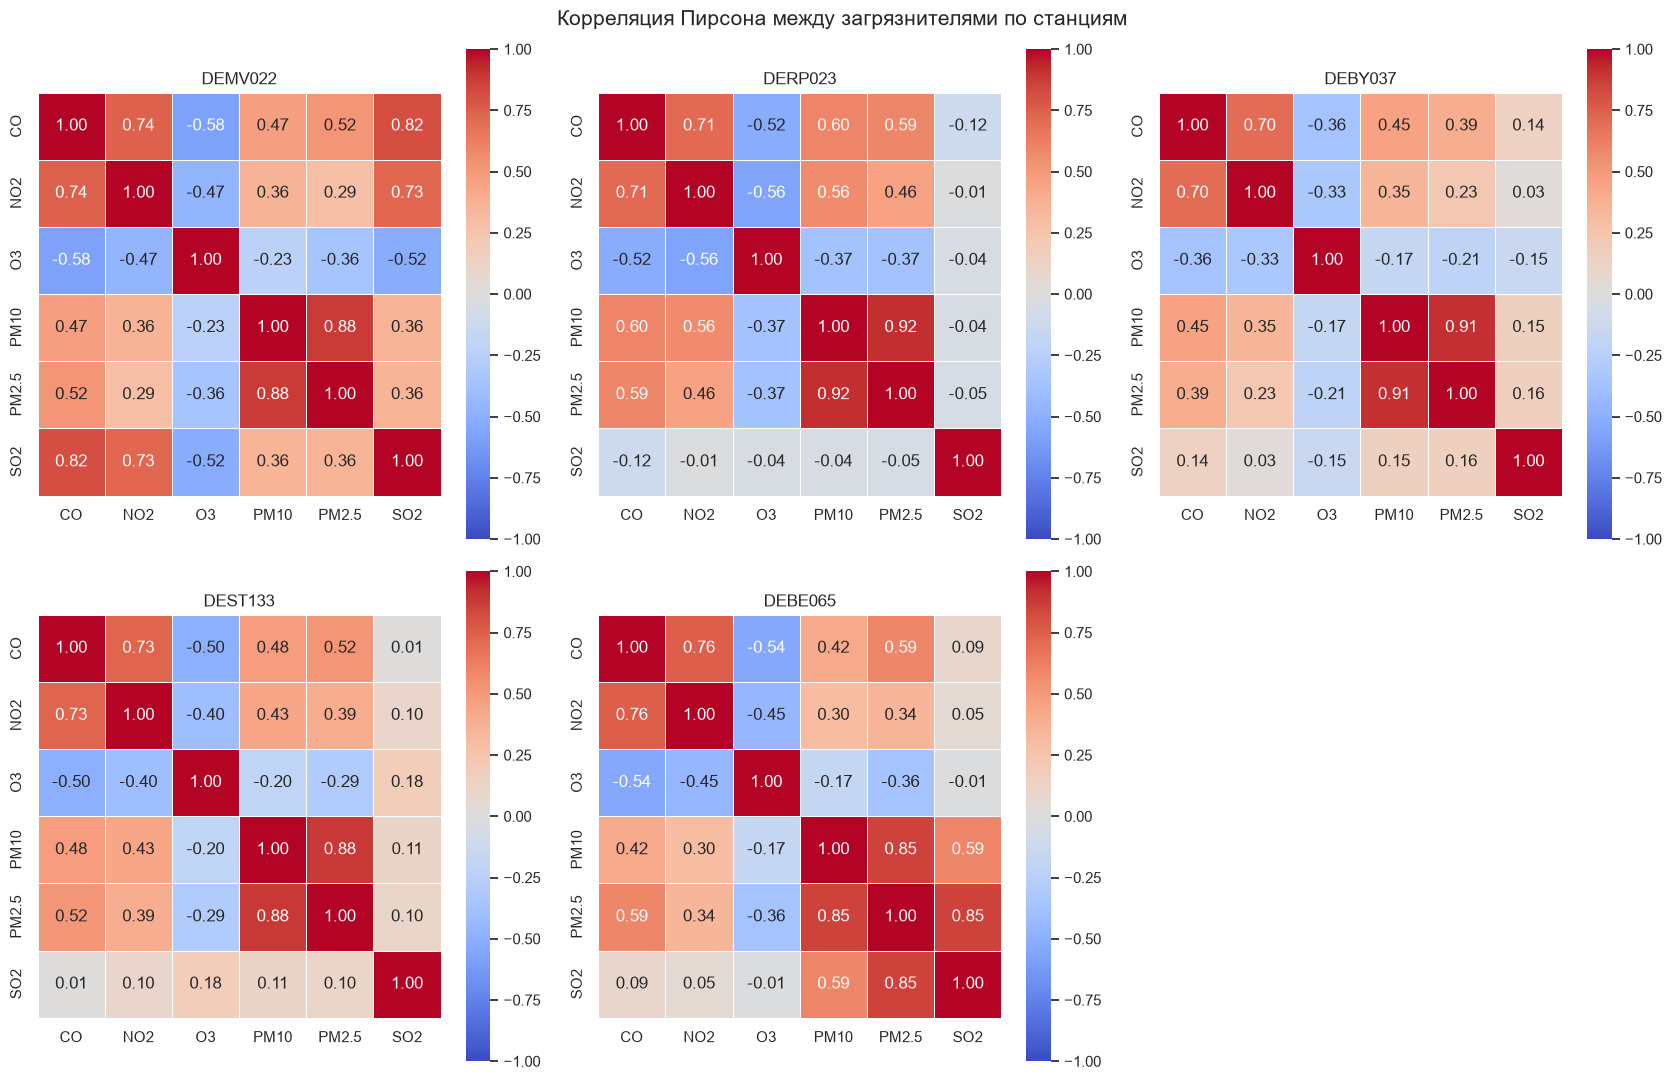

In [81]:
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()

for ax, station in zip(axes, STATIONS):
    sns.heatmap(
        pearson_correlation_matrices[station],
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(station)

axes[-1].axis("off")

fig.suptitle(
    "Корреляция Пирсона между загрязнителями по станциям",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 8.2 Ранговая корреляция Спирмена

Для дополнительного исследования взаимосвязей между загрязнителями рассчитываются коэффициенты ранговой корреляции Спирмена отдельно для каждой станции.

В отличие от корреляции Пирсона, метод Спирмена основан на рангах наблюдений и позволяет выявлять монотонные взаимосвязи, не обязательно линейные.

In [ ]:
spearman_correlation_matrices = {}

for station in STATIONS:
    station_values = concentration_data.loc[
        concentration_data["station_code"] == station,
        POLLUTANTS
    ]

    spearman_correlation_matrices[station] = (
        station_values.corr(method="spearman")
    )

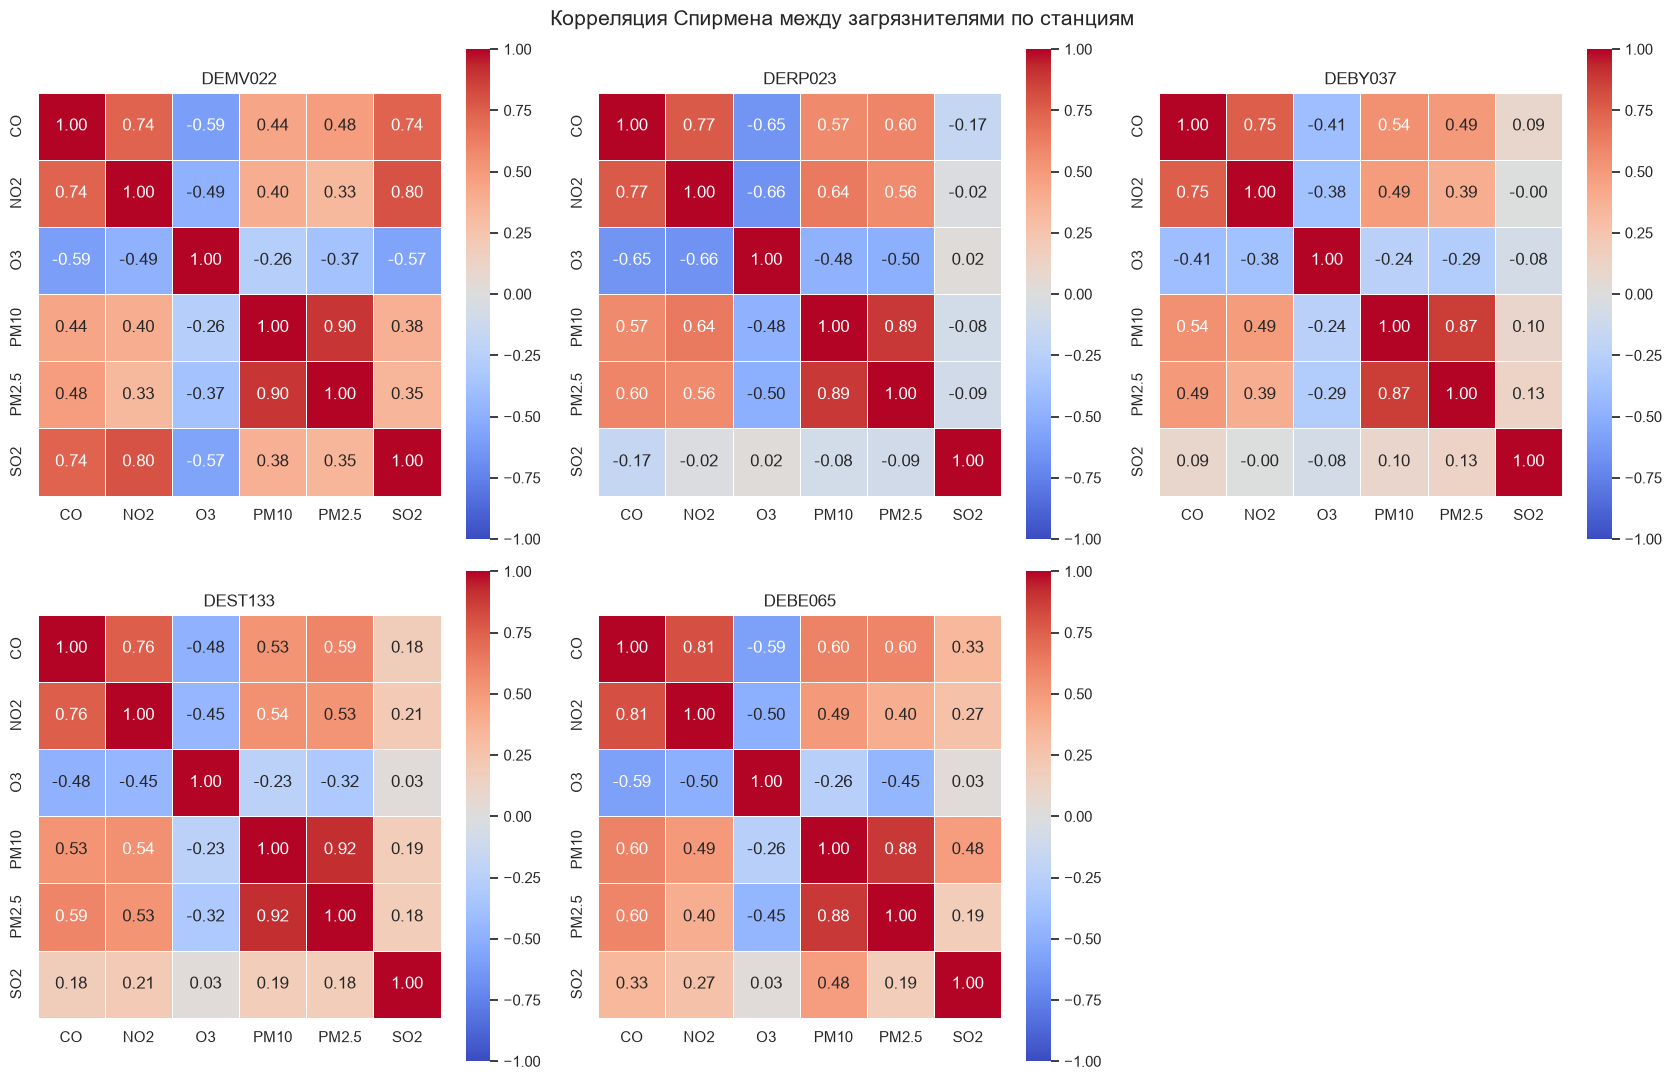

In [82]:
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()

for ax, station in zip(axes, STATIONS):
    sns.heatmap(
        spearman_correlation_matrices[station],
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(station)

axes[-1].axis("off")

fig.suptitle(
    "Корреляция Спирмена между загрязнителями по станциям",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 8.3 Сопоставление корреляции Пирсона и Спирмена

Для оценки устойчивости выявленных взаимосвязей сопоставляются коэффициенты корреляции Пирсона и Спирмена.

Оба метода рассчитываются отдельно для каждой станции. Для обобщённого сравнения используется медиана коэффициентов по пяти станциям.

Это позволяет определить, какие взаимосвязи между загрязнителями повторяются на разных станциях и насколько результаты зависят от выбранного метода корреляции.

In [83]:
pearson_stack = np.stack([
    matrix.values
    for matrix in pearson_correlation_matrices.values()
])

spearman_stack = np.stack([
    matrix.values
    for matrix in spearman_correlation_matrices.values()
])

pearson_summary = pd.DataFrame(
    np.nanmedian(pearson_stack, axis=0),
    index=POLLUTANTS,
    columns=POLLUTANTS
)

spearman_summary = pd.DataFrame(
    np.nanmedian(spearman_stack, axis=0),
    index=POLLUTANTS,
    columns=POLLUTANTS
)

pearson_station_count = np.isfinite(pearson_stack).sum(axis=0)
spearman_station_count = np.isfinite(spearman_stack).sum(axis=0)

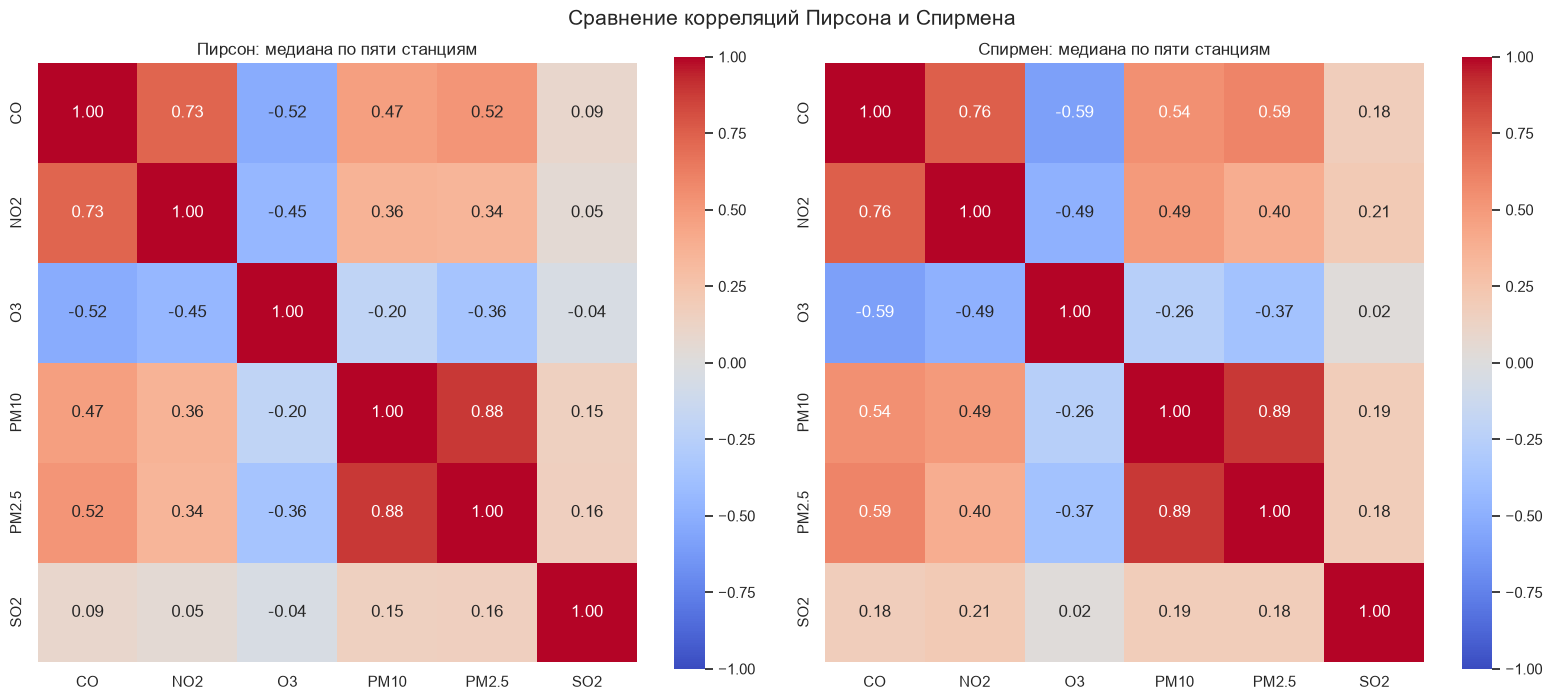

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(
    pearson_summary,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Пирсон: медиана по пяти станциям")

sns.heatmap(
    spearman_summary,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Спирмен: медиана по пяти станциям")

fig.suptitle(
    "Сравнение корреляций Пирсона и Спирмена",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 8.4 Выводы корреляционного анализа

Наиболее сильная положительная связь обнаружена между PM10 и PM2.5: коэффициенты Пирсона и Спирмена составляют 0,884 и 0,888 соответственно. Также выраженная положительная связь наблюдается между CO и NO2 (0,730 и 0,756).

Отрицательные взаимосвязи выявлены между CO и O3, а также между NO2 и O3. Наиболее выраженная из них наблюдается для пары CO — O3.

Сопоставление двух методов показывает, что в целом направления и сила выявленных взаимосвязей достаточно близки. Наибольшие различия обнаружены для пар NO2 — SO2 и NO2 — PM10.

Таким образом, корреляционный анализ позволил выявить наиболее выраженные взаимосвязи между загрязнителями.

# 9. Итоговые выводы EDA

В ходе разведочного анализа были исследованы данные о концентрациях шести загрязнителей (CO, NO2, O3, PM10, PM2.5 и SO2) на пяти выбранных станциях Германии за период 2015–2024 годов.

### Структура и качество данных

Итоговый набор данных содержит 438 360 часовых наблюдений и 23 столбца. Каждая из пяти станций представлена 87 672 наблюдениями. Проверки подтвердили отсутствие дубликатов и пропусков в последовательности временных меток.

Общая доля доступных измерений с учетом статусов Validity = 1 и Validity = 2 составляет 81,56%. При этом полнота одновременных измерений всех шести загрязнителей существенно различается между станциями: от 4,14% на DEBE065 до 94,58% на DEMV022.

### Распределения концентраций

Количество валидных измерений зависит от загрязнителя. Наибольшая доля наблюдений приходится на CO (90,10%), NO2 (89,53%) и PM10 (89,46%). Наименьшая — на SO2 (27,55%).

Все шесть распределений имеют положительную асимметрию. Особенно выраженная асимметрия наблюдается у PM10, PM2.5 и SO2. Метод межквартильного размаха также выявил потенциально экстремальные значения, доля которых составляет от 0,94% для O3 до приблизительно 5% для PM2.5 и SO2.

### Различия между станциями

Сравнение медианных концентраций показывает, что различия между станциями зависят от загрязнителя.

На DEBY037 наблюдаются наибольшие медианные концентрации CO и NO2, на DEBE065 — PM10 и PM2.5, на DEST133 — O3, а на DERP023 — SO2.

При этом сопоставимость результатов ограничена неодинаковой полнотой измерений на отдельных станциях.

### Временная динамика

Годовой анализ показывает снижение медианных концентраций CO, NO2 и PM10 на выбранных станциях. Для PM2.5 снижение прослеживается на большинстве станций, тогда как для O3 преимущественно наблюдается увеличение медианных концентраций.

Суточный анализ показывает наиболее выраженную закономерность для O3: минимальные медианные концентрации наблюдаются около 6:00, а максимальные — преимущественно в период с 13:00 до 15:00.

### Корреляционный анализ

Корреляционный анализ выявил наиболее сильную положительную взаимосвязь между PM10 и PM2.5: медианные коэффициенты Пирсона и Спирмена по пяти станциям составляют 0,884 и 0,888 соответственно.

Также выраженная положительная связь наблюдается между CO и NO2 (0,730 и 0,756).

Отрицательные взаимосвязи обнаружены между CO и O3, а также между NO2 и O3. В целом результаты двух методов показывают сходные направления взаимосвязей, хотя для отдельных пар загрязнителей наблюдаются различия в силе корреляции.